# Section 4.2: Held-Out Survey Validation Dynamics

This notebook programmatically extracts Epoch 1 training and validation trajectories from the `GroupedTrainer` state checkpoints (`Kev 0.8B`, `Kev 4B`, and `Kev 9B`) to produce the validation summary table (`#tbl-validation`) and validation trajectory figure (`#fig-validation-curves`) for Section 4.2 of the manuscript.

## 1. Setup, Academic Palette, & Loading Epoch 1 State Histories

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from cycler import cycler

CODE_DIR = Path("../..").resolve()
RUNS_DIR = CODE_DIR / "runs"
FIG_DIR = CODE_DIR.parent / "manuscript" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Standard academic palettes and neutral structural tones from code/plot.md
PALETTES: dict[str, list[str]] = {
    "nature": ["#1F3B5B", "#B84A39", "#2A7B6F", "#D4912A", "#6A4C7D", "#5C768D"],
    "lancet": ["#1B365D", "#9E2A2B", "#2E8B78", "#D9822B", "#6F5091", "#4A6F8A"],
}

NEUTRALS: dict[str, str] = {
    "text": "#2B2B2B",
    "muted": "#52514E",
    "ref_line": "#6E6A64",
    "baseline": "#9A9893",
    "grid": "#D4D2CC",
    "legend_edge": "#E0DED8",
}

def set_academic_palette(name: str = "nature") -> list[str]:
    if name not in PALETTES:
        raise ValueError(f"Unknown palette {name!r}, expected one of {list(PALETTES.keys())}")
    colors = PALETTES[name]
    plt.rcParams["axes.prop_cycle"] = cycler(color=colors)
    return colors

PALETTE_NAME = "nature"
PAL = set_academic_palette(PALETTE_NAME)

N_TRAIN_OBS = 1_881_950
N_VALID_OBS = 13_183
N_VALID_QS = 18

MODEL_SPECS = [
    {
        "label": "Kev 0.8B",
        "params_b": 0.8,
        "run_name": "kev-0.8b-resp-issp+twin2k-grouped-newvalid",
        "steps_per_epoch": 6094,
        "color": PAL[0],
    },
    {
        "label": "Kev 4B",
        "params_b": 4.0,
        "run_name": "kev-4b-resp-issp+twin2k-grouped-newvalid",
        "steps_per_epoch": 12185,
        "color": PAL[1],
    },
    {
        "label": "Kev 9B",
        "params_b": 9.0,
        "run_name": "kev-9b-resp-issp+twin2k-grouped-newvalid",
        "steps_per_epoch": 3519,
        "color": PAL[2],
    },
]

def load_epoch1_trajectory(spec: dict) -> tuple[pd.DataFrame, pd.DataFrame, dict, dict]:
    run_dir = RUNS_DIR / spec["run_name"]
    st = torch.load(run_dir / "last" / "trainer_state.pt", map_location="cpu", weights_only=False)
    with open(run_dir / "best" / "metrics.json") as f:
        best_metrics = json.load(f)
    with open(run_dir / "last" / "metrics.json") as f:
        last_metrics = json.load(f)

    steps_ep1 = spec["steps_per_epoch"]
    if st["step"] != steps_ep1:
        raise ValueError(f"Expected {steps_ep1} steps for {spec['label']}, got {st['step']}")

    val_df = pd.DataFrame(st["val_rows"]).copy()
    val_df["epoch_progress"] = val_df["step"] / float(steps_ep1)
    val_df["obs_millions"] = val_df["epoch_progress"] * (N_TRAIN_OBS / 1e6)
    val_df["model"] = spec["label"]

    train_df = pd.DataFrame({
        "step": st["history"]["step"],
        "train_step_kl": st["history"]["step_kl"],
    })
    train_df["epoch_progress"] = train_df["step"] / float(steps_ep1)
    train_df["model"] = spec["label"]

    return val_df, train_df, best_metrics, last_metrics

val_dfs = {}
train_dfs = {}
best_ckpt_info = {}
last_ckpt_info = {}

for spec in MODEL_SPECS:
    vdf, tdf, bm, lm = load_epoch1_trajectory(spec)
    label = spec["label"]
    val_dfs[label] = vdf
    train_dfs[label] = tdf
    best_ckpt_info[label] = bm
    last_ckpt_info[label] = lm
    print(
        f"{label:8s} | Epoch 1 evals={len(vdf):3d} | "
        f"Base valid_kl={vdf.iloc[0]['valid_kl']:.4f} -> "
        f"Best valid_kl={bm['eval_metrics']['valid']['dist_kl']:.4f} (step {bm['step']}/{spec['steps_per_epoch']}) -> "
        f"End Ep1 valid_kl={lm['eval_metrics']['valid']['dist_kl']:.4f}"
    )

Kev 0.8B | Epoch 1 evals=123 | Base valid_kl=2.4262 -> Best valid_kl=1.7963 (step 2100/6094) -> End Ep1 valid_kl=1.8141
Kev 4B   | Epoch 1 evals= 73 | Base valid_kl=2.3586 -> Best valid_kl=1.7431 (step 8200/12185) -> End Ep1 valid_kl=1.7604
Kev 9B   | Epoch 1 evals= 72 | Base valid_kl=2.3983 -> Best valid_kl=1.7377 (step 2100/3519) -> End Ep1 valid_kl=1.7589


## 2. Main-Text Table: Held-Out Survey Validation Cross-Entropy (`#tbl-validation`)

This table summarizes choice cross-entropy (in bits) across the three model scales (`Kev 0.8B`, `Kev 4B`, and `Kev 9B`) on the $13,183$ held-out survey validation observations ($18$ unseen `US ISSP` and `Twin-2K-500` questions).

In [2]:
summary_rows = []

for spec in MODEL_SPECS:
    label = spec["label"]
    vdf = val_dfs[label].reset_index(drop=True)
    bm = best_ckpt_info[label]
    lm = last_ckpt_info[label]

    base_row = vdf.iloc[0]
    if base_row["step"] != 0:
        raise ValueError(f"Expected step 0 at first row for {label}, got {base_row['step']}")

    base_val_ce = float(base_row["valid_kl"])
    best_step = int(bm["step"])
    best_epoch_prog = best_step / float(spec["steps_per_epoch"])
    best_val_ce = float(bm["eval_metrics"]["valid"]["dist_kl"])
    end_val_ce = float(lm["eval_metrics"]["valid"]["dist_kl"])
    val_rel_change = (best_val_ce - base_val_ce) / base_val_ce * 100.0

    summary_rows.append({
        "Model": label,
        "Base valid CE": f"{base_val_ce:.4f}",
        "FT valid CE (best)": f"{best_val_ce:.4f}",
        "FT valid CE (end Ep. 1)": f"{end_val_ce:.4f}",
        "Valid CE change": f"{val_rel_change:.1f}%",
        "Best ckpt (epoch)": f"{best_epoch_prog:.2f}",
    })

tbl_validation_df = pd.DataFrame(summary_rows)
display(tbl_validation_df)

colalign = ("left",) + ("right",) * (len(tbl_validation_df.columns) - 1)
print(tbl_validation_df.to_markdown(index=False, disable_numparse=True, colalign=colalign))
print("\n: Choice cross-entropy on the held-out survey validation split {#tbl-validation}")

,Model,Base valid CE,FT valid CE (best),FT valid CE (end Ep. 1),Valid CE change,Best ckpt (epoch)
0,Kev 0.8B,2.4262,1.7963,1.8141,-26.0%,0.34
1,Kev 4B,2.3586,1.7431,1.7604,-26.1%,0.67
2,Kev 9B,2.3983,1.7377,1.7589,-27.5%,0.60


| Model    |   Base valid CE |   FT valid CE (best) |   FT valid CE (end Ep. 1) |   Valid CE change |   Best ckpt (epoch) |
|:---------|----------------:|---------------------:|--------------------------:|------------------:|--------------------:|
| Kev 0.8B |          2.4262 |               1.7963 |                    1.8141 |            -26.0% |                0.34 |
| Kev 4B   |          2.3586 |               1.7431 |                    1.7604 |            -26.1% |                0.67 |
| Kev 9B   |          2.3983 |               1.7377 |                    1.7589 |            -27.5% |                0.60 |

: Choice cross-entropy on the held-out survey validation split {#tbl-validation}


## 3. Main-Text Figure: Epoch 1 Held-Out Survey Validation Trajectories (`#fig-validation-curves`)

We plot choice cross-entropy across the first epoch of training ($1,881,950$ survey observations) for `Kev 0.8B`, `Kev 4B`, and `Kev 9B` on the $13,183$ held-out survey validation observations ($18$ unseen questions) using the repository's Nature/Lancet editorial styling (`code/plot.md`).

Saved figure to /home/dw/github/decision-models-finetuning/manuscript/figures/validation_trajectories.pdf and /home/dw/github/decision-models-finetuning/manuscript/figures/validation_trajectories.png


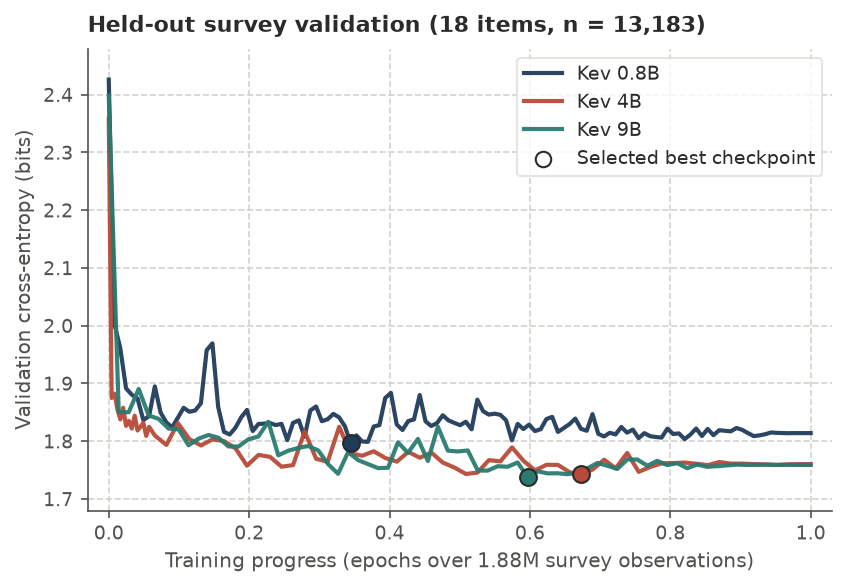

In [3]:
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 9.5,
    "axes.titlesize": 10.5,
    "axes.labelsize": 9.5,
    "xtick.labelsize": 9.0,
    "ytick.labelsize": 9.0,
    "legend.fontsize": 9.0,
    "figure.dpi": 150,
})

fig, ax = plt.subplots(1, 1, figsize=(6.4, 4.0), dpi=150)

for spec in MODEL_SPECS:
    label = spec["label"]
    color = spec["color"]
    vdf = val_dfs[label].sort_values("epoch_progress")
    bm = best_ckpt_info[label]

    ax.plot(
        vdf["epoch_progress"],
        vdf["valid_kl"],
        label=label,
        color=color,
        linewidth=2.0,
        alpha=0.95,
        zorder=3,
    )
    best_prog = bm["step"] / float(spec["steps_per_epoch"])
    best_val = bm["eval_metrics"]["valid"]["dist_kl"]
    ax.scatter(
        [best_prog],
        [best_val],
        color=color,
        edgecolor=NEUTRALS["text"],
        linewidth=1.0,
        s=65,
        zorder=5,
        marker="o",
    )

ax.scatter(
    [],
    [],
    color="white",
    edgecolor=NEUTRALS["text"],
    linewidth=1.0,
    s=55,
    marker="o",
    label="Selected best checkpoint",
)

ax.set_title("Held-out survey validation (18 items, n = 13,183)", color=NEUTRALS["text"], fontsize=10.5, fontweight="bold", loc="left", pad=8)
ax.set_xlabel("Training progress (epochs over 1.88M survey observations)", color=NEUTRALS["muted"], fontsize=9.5)
ax.set_ylabel("Validation cross-entropy (bits)", color=NEUTRALS["muted"], fontsize=9.5)
ax.set_xlim(-0.03, 1.03)
ax.set_ylim(1.68, 2.48)
ax.tick_params(axis="both", colors=NEUTRALS["muted"], labelsize=9.0)
ax.grid(True, color=NEUTRALS["grid"], linestyle="--", linewidth=0.8, zorder=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color(NEUTRALS["muted"])
ax.spines["bottom"].set_color(NEUTRALS["muted"])
ax.legend(
    frameon=True,
    facecolor="white",
    edgecolor=NEUTRALS["legend_edge"],
    loc="upper right",
    labelcolor=NEUTRALS["text"],
)

pdf_path = FIG_DIR / "validation_trajectories.pdf"
png_path = FIG_DIR / "validation_trajectories.png"
fig.savefig(pdf_path, bbox_inches="tight")
fig.savefig(png_path, dpi=300, bbox_inches="tight")
print(f"Saved figure to {pdf_path} and {png_path}")
plt.show()